For NPIX MSIT data: scroll raw vs interpolation (kriging) AP data to see whether units are still there

There are three clocks to keep track of:
- **"shared time" (aka unified aka Open Ephys/TTL time aka Npix time)**
    - This is the first clock that starts, when Open Ephys is started.
    - shared time = continuous.dat time + get_start_time() (e.g., for MSIT 014 get_start_time() is 72.2996)
- **"continuous.dat time" aka "file time"**
    - This is seconds from when the continuous.dat started recording. Eric's code is all in continuous.dat time.
- **"segment time"**
    - This is seconds in the segment that is cut prior to interpolation (also what shows up in Phy)
    - segment time = continuous.dat time - make_segment start time
    - thus, segment time = shared time - get_start_time() - make_segment start time
    - E.g., for MSIT 014, to find the segment time for a shared time of 1000 s: 1000 - 72.2996 - 906 = 21.7004 s

In this notebook, BOTH recordings are put on the **shared** clock, so the widget time box is **shared time**. Segment time is printed next to it.
The general idea is to cut out the raw continuous.dat file in exactly the same spots as the segment, line them up, and scroll them simultaneously. 

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import spikeinterface.full as si
import spikeinterface.extractors as se
from pathlib import Path

# ---- CHANGE THESE FOR A NEW PATIENT / SEGMENT ----
name = "NPIX_MSIT_014"
folder = Path(r"C:\Users\wongbe\Desktop\PROJECTS_PC\npix_data_bhw\2026-10-02_15-08-00_NPIX_MSIT_014")
seg_name = "seg_t890_g060" # the make_segment folder name
# -------------------------------------------------------

ap_dir = folder / "Record Node 123" / "experiment1" / "recording1" / "continuous" / "OneBox-122.ProbeA-AP"
seg_dir = ap_dir / seg_name # make_segment output (a raw copy of the segment)
interp_path = seg_dir / f"interp{seg_name}" / f"interp{seg_name}.dat" # MATLAB kriging output

# load the raw recording (same as RAW_DATA_EXPLORE_BHW)
raw_AP = se.read_openephys(folder, stream_name="Record Node 123#OneBox-122.ProbeA-AP")
fs = raw_AP.get_sampling_frequency() # 30000 Hz
t0 = raw_AP.get_start_time() # **shared** time of the first sample of continuous.dat
print(raw_AP)
print(f"get_start_time = {t0}s this is the start time of continuous.dat on the shared clock") # e.g., 72.2996 for 014

%matplotlib inline

OpenEphysBinaryRecordingExtractor: 384 channels - 30.0kHz - 1 segments - 48,159,900 samples 
                                   1,605.33s (26.76 minutes) - int16 dtype - 34.45 GiB
get_start_time = 72.2996s this is the start time of continuous.dat on the shared clock


In [3]:
# find make_segment start, in continuous.dat time. make_segment.py writes this to segment_t0.txt, we can read that. 
seg_start = float((seg_dir / "segment_t0.txt").read_text())
print(f"seg_start = {seg_start}s (this is in continuous.dat time)") # e.g., 906.0 for MSIT 014 seg_t890_g060

#----- HOWEVER, using times does not align exactly, so we have to align by sample number ----- 

# make_segment.py turns the start time into a sample number with int(t0 * FS), so we'll use the exact same formula
F0 = int(seg_start * 30000) # first frame of the segment inside continuous.dat
print(f"segment first frame inside continuous.dat = {F0}") # eg., 27,180,000 for 906.0s in MSIT 014

seg_start = 906.0s (this is in continuous.dat time)
segment first frame inside continuous.dat = 27180000


In [4]:
# interp: a plain binary file, so we tell SI its format by hand (int16, 384 channels, 30 kHz)
# MATLAB writes channels in the same order as continuous.dat, so we give it the raw channel names
interp = si.read_binary(interp_path, sampling_frequency=fs, dtype="int16", num_channels=384,
                        channel_ids=raw_AP.channel_ids)
interp.set_channel_locations(raw_AP.get_channel_locations()) # same probe positions as raw (for depth selection)

# total number of frames in the interp segment, from SI
n_frames = interp.get_num_frames()
print(f"{n_frames} total frames in interp segment = {interp.get_duration()} sec") # eg. 19,110,000 frames = 637.0 s for 014

# raw: cut out exactly the frames make_segment copied. frame_slice keeps the shared times
raw_seg = raw_AP.frame_slice(start_frame=F0, end_frame=F0 + n_frames)

# ----- this is KEY for aligning the times. set_times will give the interp segment the same time as the raw_segment (this is in SHARED time). It just changes the label of the time
# without this, interp would start at 0 s (segment time)
# SI notes that set_times doesn't carry through preprocessing. We set it BEFORE preprocessing, so for the purposes of this notebook it should carry through.
interp.set_times(raw_seg.get_times())

print(raw_seg)
print(interp)

19110000 total frames in interp segment = 637.0 sec
FrameSliceRecording: 384 channels - 30.0kHz - 1 segments - 19,110,000 samples 
                     637.00s (10.62 minutes) - int16 dtype - 13.67 GiB
BinaryRecordingExtractor: 384 channels - 30.0kHz - 1 segments - 19,110,000 samples 
                          637.00s (10.62 minutes) - int16 dtype - 13.67 GiB
  file_paths: ['C:\\Users\\wongbe\\Desktop\\PROJECTS_PC\\npix_data_bhw\\2026-10-02_15-08-00_NPIX_MSIT_014\\Record Node 123\\experiment1\\recording1\\continuous\\OneBox-122.ProbeA-AP\\seg_t890_g060\\interpseg_t890_g060\\interpseg_t890_g060.dat']


c:\Users\wongbe\Desktop\PROJECTS_PC\bhw_code\neuro-env-pc.venv\Lib\site-packages\spikeinterface\core\baserecording.py:506: UserWarning: Setting times with Recording.set_times() is not recommended because times are not always propagated across preprocessingUse this carefully!
  warnings.warn(


In [5]:
### --------- TIMING CHECKS -----------
# We need to make sure these segments are aligned.

# segments should be the same length and the first sample should be at the same shared time.
print(f" {raw_seg.get_num_frames(), interp.get_num_frames()} make sure these are equal!") # must be equal
print(f"{raw_seg.get_start_time()}, {t0 + seg_start} make sure these are equal!") # must be equal. 978.2996 for 014
print(np.array_equal(raw_seg.get_times(), interp.get_times()))  # True = every sample has the identical shared time


 (19110000, 19110000) make sure these are equal!
978.2996, 978.2996 make sure these are equal!
True


In [6]:
# same display chain as RAW_DATA_EXPLORE_BHW: bandpass -> phase shift -> CMR
raw_hp = si.bandpass_filter(raw_seg, freq_min=300, freq_max=3000, margin_ms=20)
raw_ps = si.phase_shift(raw_hp)
raw_show = si.common_reference(raw_ps)

# interp: NO phase_shift, MATLAB already phase shifted before kriging ("ADC phase shift ON")
interp_hp = si.bandpass_filter(interp, freq_min=300, freq_max=3000, margin_ms=20)
interp_show = si.common_reference(interp_hp)

# times survived preprocessing?
print(np.array_equal(raw_show.get_times(), interp_show.get_times())) # True

True


Now we can scroll both together

Layer dropdown on the left: **ALL** overlays raw and interp in different colors. The time box and slider are **shared time**. The cell below prints the valid shared time range for this segment (eg 978.3 to 1615.3 s for 014 seg_t890_g060).

In [7]:
%matplotlib widget
plt.close("all")

print("valid shared time range:", raw_show.get_start_time(), "to", raw_show.get_end_time())

# use this to find segment time
t_show = 1000 # whatever time you want, shared time, seconds
print("segment time:", t_show - t0 - seg_start)

# dict = several layers on ONE time slider. Both are read at the same frames
w = si.plot_traces({"interp shared time": interp_show, "raw shared time": raw_show}, backend="ipywidgets",
                   channel_ids=raw_show.channel_ids[0:20],
                   time_range=(t_show, t_show + 1), color="red")

valid shared time range: 978.2996 to 1615.2995666666666
segment time: 21.700399999999945


AppLayout(children=(TimeSlider(children=(Dropdown(description='Segment', options=(0,), value=0), Button(icon='…

In [12]:
# FASTER widget: filter a chunk ONCE (using all CPU cores), keep it in RAM, then scroll inside that chunk
# RAM: ~92 MB per second of chunk (both layers, 384 channels, float32). 60 s = ~5.5 GB
%matplotlib widget
plt.close("all")

# free the previous chunk first, so rerunning with a new t_cache doesn't hold two chunks in RAM
if "raw_mem" in globals():
    del w_mem, raw_mem, interp_mem

t_cache = 980 # shared time, seconds, start of the chunk to load into RAM
cache_len = 180 # seconds of chunk

# use SI to find the frame for t_cache, then cut BOTH layers at the same frames
s = raw_show.time_to_sample_index(t_cache)
n = int(cache_len * fs)
raw_mem = raw_show.frame_slice(start_frame=s, end_frame=s + n).save(format="memory", n_jobs=-1, progress_bar=True)
interp_mem = interp_show.frame_slice(start_frame=s, end_frame=s + n).save(format="memory", n_jobs=-1, progress_bar=True)

print(f" {np.max(np.abs(raw_mem.get_times() - interp_mem.get_times()))} THIS SHOULD BE NEARLY ZERO, ie 1e-12 or something") # make sure this is almost zero

print("chunk shared time range:", raw_mem.get_start_time(), "to", raw_mem.get_end_time())

w_mem = si.plot_traces({"interp": interp_mem, "raw": raw_mem}, backend="ipywidgets",
                       channel_ids=raw_mem.channel_ids[0:20],
                       time_range=(t_cache, t_cache + 1), color="red")

write_memory_recording (workers: 24 processes spawn):   0%|          | 0/180 [00:00<?, ?it/s]

write_memory_recording (workers: 24 processes spawn):   0%|          | 0/180 [00:00<?, ?it/s]

 2.2737367544323206e-13 THIS SHOULD BE NEARLY ZERO, ie 1e-12 or something
chunk shared time range: 980.0 to 1159.9999666666668


c:\Users\wongbe\Desktop\PROJECTS_PC\bhw_code\neuro-env-pc.venv\Lib\site-packages\spikeinterface\core\baserecording.py:506: UserWarning: Setting times with Recording.set_times() is not recommended because times are not always propagated across preprocessingUse this carefully!
  warnings.warn(


AppLayout(children=(TimeSlider(children=(Dropdown(description='Segment', options=(0,), value=0), Button(icon='…

Side-by-side snapshot at one time and depth. Note: each panel is scaled on its own, so compare amplitudes in the widget above (ALL is in one scale).

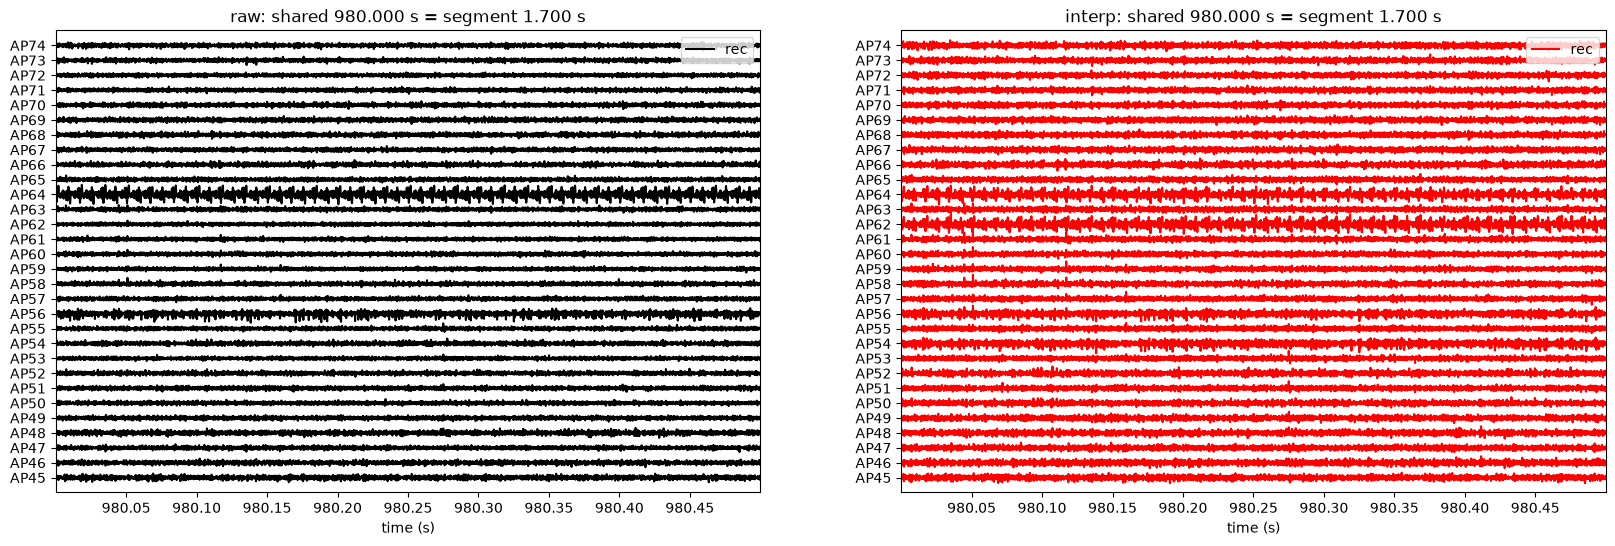

In [18]:
%matplotlib inline
plt.close("all")

t_snap = 980 # shared time, seconds (start of the 1 s window you want to see)
ch_first =45 # first channel index to show
n_ch = 30 # number of channels to show

chans = raw_show.channel_ids[ch_first:ch_first + n_ch]

fig, axes = plt.subplots(1, 2, figsize=(20, 6))

for ax, rec, title, col in zip(axes, [raw_show, interp_show], ["raw", "interp"], ["black", "red"]): # same channels, same time window
    si.plot_traces(rec, channel_ids=chans, time_range=(t_snap, t_snap + 0.5),
                   backend="matplotlib", show_channel_ids=True, ax=ax, color=col)
    ax.set_title(f"{title}: shared {t_snap:.3f} s = segment {t_snap - t0 - seg_start:.3f} s")
